# GutSignal v4: диагностика КРР по микробиому

**Литература и актуальность.** КРР: ~1.9 млн новых случаев в год, 2-е место по смертности (Bray 2024, GLOBOCAN 2022). Мета-анализы: сигнатура оральных родов (*Fusobacterium, Parvimonas, Peptostreptococcus, Gemella, Porphyromonas, Solobacterium*), AUROC 0.71–0.91 между исследованиями (Wirbel 2019; Thomas 2019; Piccinno 2025). Возраст, ИМТ и страна искажают сигнал (Vujkovic-Cvijin 2020).

**Разбиение.** 80/20 по стране × метке, seed 42: train 332 (167 control / 165 case), validation 83 (43 / 40), исключено 0; CV 5 × 5 только в train.

**Признаки.** Таксоны в ≥ 5 % образцов (677; в финале 681): log10(доля + 1e-5) минус линейный вклад возраста, log10(глубины) и страны; + сумма и число ротовых таксонов, богатство, Шеннон. **Отбор:** только этот фильтр. **Модель:** 0.7 · лес + 0.3 · L2-логрег.

**Ковариаты.** Больные старше (p 0.003), глубина p 0.034; страна, пол, ИМТ p > 0.19. В Германии глубина сама даёт AUC 0.87 (батч-эффект). **Ограничение:** остатки делают их читаемыми для леса, скор частично зависит от глубины: перемешивание глубины и возраста внутри страны −0.080 и −0.036 AUC на validation; при выравнивании по стране, возрасту и глубине v3 0.904, без остатков 0.908.

**Результаты** (CV ± SD фолдов; новая страна; выровн. по стране и возрасту): LASSO 0.828; 0.792; 0.837. Лес + литература 0.887; 0.864; 0.871. v2 0.928; 0.877; 0.905. **v3 0.936 ± 0.030; 0.890; 0.918** (к v2 +0.008, p = 0.13; из ~40 вариантов). Перемешанные метки 0.528. **ROC AUC на validation: 0.9076** (ДИ 0.842–0.960; v2 0.8855; без остатков 0.8035). `label` — вероятность КРР. **Поиск улучшений (v4).** 30 вариантов (модели, признаки, глубина, пол) проверены по тому же правилу и на других фолдах: ни один не принят, финал = v3 (раздел 13). Сдвига train → test нет.

## 0. Настройки (seed = 42)

In [1]:
import os, random, sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy.spatial.distance import pdist, squareform
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr, combine_pvalues, t as t_dist
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, LinearRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

SEED = 42
random.seed(SEED); np.random.seed(SEED)          # глобальные генераторы; все модели и rng ниже тоже получают SEED явно
def find_csv(name):
    """Файл рядом с ноутбуком (локально) или в папке датасетов платформы (datasets/<набор>/<файл>)."""
    if Path(name).exists():
        return name
    for root in (os.environ.get("PLATFORM_DATASET_DIR"), "datasets"):
        if root and Path(root).exists():
            hits = sorted(Path(root).rglob(name))
            if hits:
                return str(hits[0])
    raise FileNotFoundError(name)


TRAIN_PATH, TEST_PATH = find_csv("train.csv"), find_csv("test.csv")
META = ["cohort", "age", "gender", "bmi", "library_size"]
PSEUDO, N_TREES = 1e-5, 500
MIN_PREV = 0.05          # таксон берём, если он есть хотя бы в 5 % образцов обучения (в v2 было 10 %)
W_RF, LR_C = 0.7, 0.01   # ансамбль = 0.7 · лес + 0.3 · L2-логрег (C = сила регуляризации)
N_JOBS = -1              # лес обучается во все ядра; предсказание всегда в 1 поток (проверка в разделе 9)
DECIMALS = 6             # label округляется до 6 знаков: убирает разницу ~1e-14 между машинами с разным числом потоков BLAS
FULL_SPEC = ("age", "depth", "cohort")          # ковариаты для остатков: возраст, log10(глубина), страна
LIT_GENERA = ["Fusobacterium", "Parvimonas", "Peptostreptococcus", "Gemella", "Porphyromonas", "Solobacterium"]
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scipy", scipy.__version__, "| SEED", SEED)

python 3.14.10 | sklearn 1.9.1 | pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1 | SEED 42


## 1. Данные (столбцы — по именам)

In [2]:
train = pd.read_csv(TRAIN_PATH).sort_values("sample_id").reset_index(drop=True)
test = pd.read_csv(TEST_PATH)
TAXA = sorted(c for c in train.columns if c not in ["sample_id", "label"] + META)
assert train["sample_id"].is_unique and test["sample_id"].is_unique
assert train[TAXA].notna().all().all() and (train[TAXA] >= 0).all().all()
assert test[["age", "library_size", "cohort"]].notna().all().all() and (test["library_size"] > 0).all() and set(test["cohort"]) <= set(train["cohort"]), "в метаданных test пропуски или незнакомая страна"
missing = sorted(set(TAXA) - set(test.columns))      # отсутствующий в test таксон не ломает решение: он заполнится нулём
print("в test нет таксонов:", len(missing))
COHORTS = sorted(train["cohort"].unique())
print("train", train.shape, "| test", test.shape, "| таксонов:", len(TAXA), "| когорты:", COHORTS)

в test нет таксонов: 0
train (415, 856) | test (160, 855) | таксонов: 849 | когорты: ['AUS', 'CHI', 'FRA', 'GER', 'USA']


## 2. Разбиение до анализа (80/20, страна × метка)

In [3]:
def split_data(train, seed=SEED, val_frac=0.20):
    train = train.sort_values("sample_id").reset_index(drop=True)
    strata = train["cohort"].astype(str) + "|" + train["label"].astype(str)
    tr_ids, va_ids = train_test_split(train["sample_id"], test_size=val_frac, stratify=strata, random_state=seed)
    return (train[train["sample_id"].isin(tr_ids)].reset_index(drop=True),
            train[train["sample_id"].isin(va_ids)].reset_index(drop=True))


train_df, validation_df = split_data(train)
assert not set(train_df["sample_id"]) & set(validation_df["sample_id"]) and len(train_df) + len(validation_df) == len(train)
assert split_data(train.sample(frac=1, random_state=SEED))[1]["sample_id"].tolist() == validation_df["sample_id"].tolist()
for name, d in [("train", train_df), ("validation", validation_df)]:
    print(f"{name:10s} {len(d)} образцов ({len(d) / len(train):.0%}): control {(d['label'] == 0).sum()}, case {(d['label'] == 1).sum()}")
print("исключено образцов: 0")
y_tr = train_df["label"].values

train      332 образцов (80%): control 167, case 165
validation 83 образцов (20%): control 43, case 40
исключено образцов: 0


## 3. Метаданные: перекосы
Case против control, внутри стран.

label   control  case  доля case
cohort                          
AUS          38    25       0.40
CHI          33    47       0.59
FRA          34    30       0.47
GER          35    34       0.49
USA          27    29       0.52
страна x диагноз: p = 0.244
пол x диагноз:    p = 0.194
age           медиана control 63 / case 65   Манн-Уитни p = 0.0028
bmi           медиана control 24.5 / case 25.2   Манн-Уитни p = 0.6
library_size  медиана control 2.389e+07 / case 2.685e+07   Манн-Уитни p = 0.034
страна  AUC глубины  p глубины  AUC возраста
   AUS        0.715      0.004         0.608
   CHI        0.286      0.001         0.630
   FRA        0.449      0.488         0.689
   GER        0.871      0.000         0.633
   USA        0.589      0.258         0.521


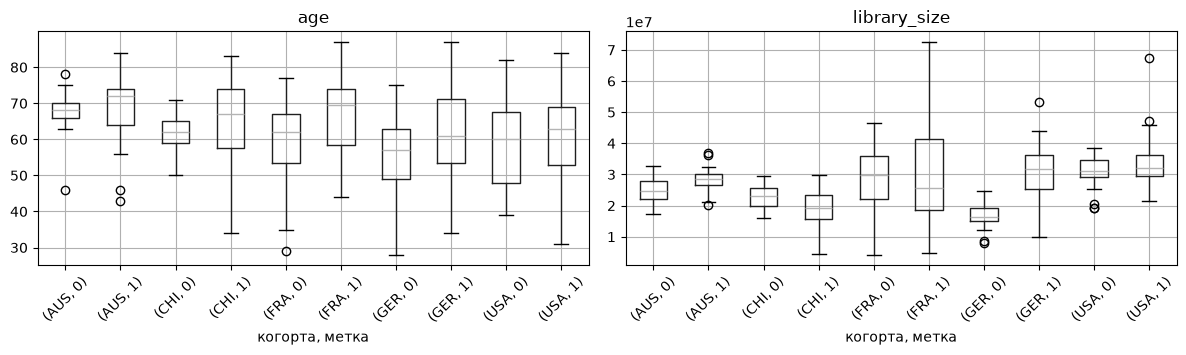

In [4]:
ct = pd.crosstab(train_df["cohort"], train_df["label"]).rename(columns={0: "control", 1: "case"})
ct["доля case"] = (ct["case"] / ct[["control", "case"]].sum(axis=1)).round(2)
print(ct.to_string())
print("страна x диагноз: p = %.3f" % chi2_contingency(ct[["control", "case"]]).pvalue)
print("пол x диагноз:    p = %.3f" % chi2_contingency(pd.crosstab(train_df["gender"], train_df["label"])).pvalue)
for col in ["age", "bmi", "library_size"]:
    a, b = (train_df.loc[train_df["label"] == k, col].dropna() for k in (0, 1))
    print(f"{col:13s} медиана control {a.median():.4g} / case {b.median():.4g}   Манн-Уитни p = {mannwhitneyu(a, b).pvalue:.2g}")

# Внутри страны: насколько одна ковариата отделяет больных от здоровых (AUC 0.5 = никак, < 0.5 = обратная связь)
rows = [(co, roc_auc_score(g["label"], g["library_size"]), mannwhitneyu(*(g.loc[g["label"] == k, "library_size"] for k in (0, 1))).pvalue,
         roc_auc_score(g["label"], g["age"])) for co, g in train_df.groupby("cohort")]
print(pd.DataFrame(rows, columns=["страна", "AUC глубины", "p глубины", "AUC возраста"]).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["age", "library_size"]):
    train_df.boxplot(column=col, by=["cohort", "label"], ax=ax, rot=45); ax.set_title(col); ax.set_xlabel("когорта, метка")
plt.suptitle(""); plt.tight_layout(); plt.show()

## 4. Микробиом: разнообразие
Шеннон, PCoA и PERMANOVA (Брей–Кёртис), только train.

индекс Шеннона, медиана:
страна  control  case     p
   AUS    3.601 3.677 0.496
   CHI    3.656 3.519 0.229
   FRA    3.914 3.880 0.941
   GER    3.830 3.900 0.862
   USA    4.119 3.900 0.131
PERMANOVA (Брей–Кёртис): страна R² = 0.069 (p = 0.001) | диагноз R² = 0.013 (p = 0.001, перестановки внутри стран)


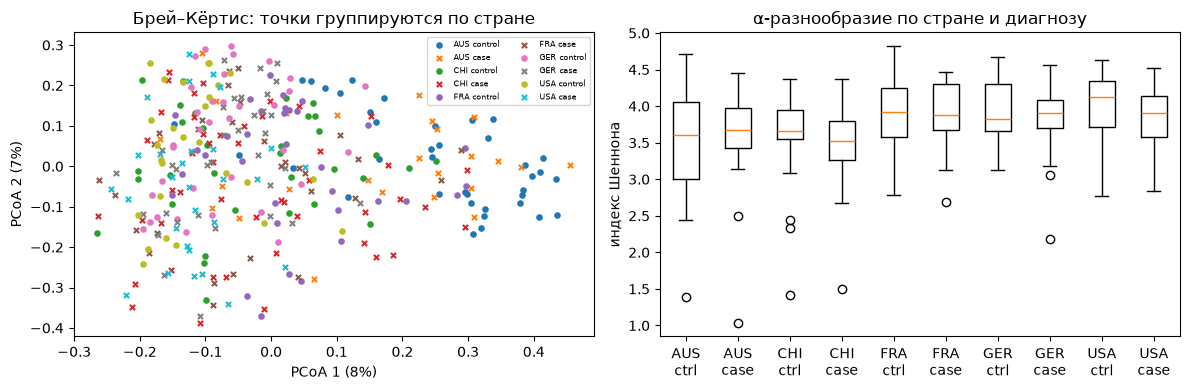

In [5]:
Xd = train_df[TAXA].to_numpy(float)
Pd = Xd / Xd.sum(axis=1, keepdims=True)                         # относительные доли (сумма = 1)
shannon_d = -np.sum(np.where(Pd > 0, Pd * np.log(np.where(Pd > 0, Pd, 1.0)), 0.0), axis=1)
co_d = train_df["cohort"].values
rows = [(co, np.median(shannon_d[(co_d == co) & (y_tr == 0)]), np.median(shannon_d[(co_d == co) & (y_tr == 1)]),
         mannwhitneyu(shannon_d[(co_d == co) & (y_tr == 1)], shannon_d[(co_d == co) & (y_tr == 0)]).pvalue) for co in COHORTS]
print("индекс Шеннона, медиана:")
print(pd.DataFrame(rows, columns=["страна", "control", "case", "p"]).round(3).to_string(index=False))

D2 = squareform(pdist(Pd, "braycurtis")) ** 2


def permanova(groups, strata=None, n_perm=999, seed=SEED):
    """PERMANOVA (Anderson 2001): доля вариации расстояний, объяснённая группами (R²), и перестановочный p."""
    n = len(groups); rng = np.random.default_rng(seed)
    sst = D2.sum() / (2 * n)

    def ssw(g):
        G = pd.get_dummies(g).to_numpy(float)
        return np.sum(np.diag(G.T @ D2 @ G) / (2 * G.sum(axis=0)))

    k = len(np.unique(groups)); w = ssw(groups); f0 = ((sst - w) / (k - 1)) / (w / (n - k)); hits = 0
    for _ in range(n_perm):
        g = groups.copy()
        if strata is None:
            g = rng.permutation(g)
        else:                                    # перестановки внутри страны: проверяем диагноз при учтённой стране
            for s in np.unique(strata):
                m = strata == s; g[m] = rng.permutation(g[m])
        ww = ssw(g); hits += ((sst - ww) / (k - 1)) / (ww / (n - k)) >= f0
    return (sst - w) / sst, (hits + 1) / (n_perm + 1)


r2_c, p_c = permanova(co_d)
r2_y, p_y = permanova(y_tr.copy(), strata=co_d)
print(f"PERMANOVA (Брей–Кёртис): страна R² = {r2_c:.3f} (p = {p_c:.3f}) | диагноз R² = {r2_y:.3f} (p = {p_y:.3f}, перестановки внутри стран)")

n = len(D2); J = np.eye(n) - 1.0 / n
vals, vecs = np.linalg.eigh(-0.5 * J @ D2 @ J); top = np.argsort(vals)[::-1][:2]
pc = vecs[:, top] * np.sqrt(vals[top]); share = vals[top] / vals[vals > 0].sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for co in COHORTS:
    for lab, mk in [(0, "o"), (1, "x")]:
        m = (co_d == co) & (y_tr == lab)
        axes[0].scatter(pc[m, 0], pc[m, 1], s=14, marker=mk, label=f"{co} {'case' if lab else 'control'}")
axes[0].set_xlabel(f"PCoA 1 ({share[0]:.0%})"); axes[0].set_ylabel(f"PCoA 2 ({share[1]:.0%})")
axes[0].set_title("Брей–Кёртис: точки группируются по стране"); axes[0].legend(fontsize=6, ncol=2)
axes[1].boxplot([shannon_d[(co_d == co) & (y_tr == lab)] for co in COHORTS for lab in (0, 1)])
axes[1].set_xticks(range(1, 2 * len(COHORTS) + 1), [f"{co}\n{'case' if lab else 'ctrl'}" for co in COHORTS for lab in (0, 1)])
axes[1].set_ylabel("индекс Шеннона"); axes[1].set_title("α-разнообразие по стране и диагнозу")
plt.tight_layout(); plt.show()

## 5. Предобработка и модель
Учится на обучающей части, применяется без пересчёта.

In [6]:
def taxa_matrix(df):
    return np.nan_to_num(df.reindex(columns=TAXA, fill_value=0.0).to_numpy(dtype=float), nan=0.0)


def genus(col):
    w = col.split()
    return w[1] if w[0] == "unknown" else w[0]


MARKER_IDX = [i for i, c in enumerate(TAXA) if genus(c) in LIT_GENERA]


def lit_features(X):
    """4 признака образца: log10 суммарной доли ротовых родов, число ротовых таксонов, богатство, индекс Шеннона."""
    M = X[:, MARKER_IDX]
    tot = X.sum(axis=1, keepdims=True)
    P = X / np.where(tot > 0, tot, 1.0)
    shannon = -np.sum(np.where(P > 0, P * np.log(np.where(P > 0, P, 1.0)), 0.0), axis=1)
    return np.column_stack([np.log10(M.sum(axis=1) + PSEUDO), (M > 0).sum(axis=1), (X > 0).sum(axis=1), shannon])


def cov_design(df, st, spec):
    """Ковариаты для регрессии: возраст, log10(глубина секвенирования), страна (one-hot). Метки здесь нет."""
    cols = []
    if "age" in spec: cols.append((df["age"].to_numpy(float) - st["age_mu"]) / st["age_sd"])
    if "depth" in spec: cols.append((np.log10(df["library_size"].to_numpy(float)) - st["dep_mu"]) / st["dep_sd"])
    if "cohort" in spec: cols += [(df["cohort"] == c).to_numpy(float) for c in COHORTS]
    return np.column_stack(cols)


def fit_preprocessing(fit_df, spec=FULL_SPEC, min_prev=MIN_PREV):
    """Учится на fit_df: какие таксоны оставить и как их log-доли линейно зависят от ковариат."""
    X = taxa_matrix(fit_df)
    keep = np.flatnonzero((X > 0).mean(axis=0) >= min_prev)
    prep = {"keep": keep, "spec": tuple(spec)}
    if spec:
        prep["st"] = dict(age_mu=fit_df["age"].mean(), age_sd=fit_df["age"].std() + 1e-9,
                          dep_mu=np.log10(fit_df["library_size"]).mean(), dep_sd=np.log10(fit_df["library_size"]).std() + 1e-9)
        prep["reg"] = LinearRegression().fit(cov_design(fit_df, prep["st"], spec), np.log10(X[:, keep] + PSEUDO))
    return prep


def apply_preprocessing(df, prep, lit=True):
    """Применяет выученное к любому df и ничего на нём не пересчитывает. Возвращает матрицу признаков."""
    X = taxa_matrix(df)
    F = np.log10(X[:, prep["keep"]] + PSEUDO)
    if prep["spec"]:
        # Остаток = log-доля минус предсказание по ковариатам. У отсутствующего таксона log-доля постоянна (-5),
        # поэтому его остаток — линейная функция возраста и глубины: лес может «прочитать» их (разделы 8, 11).
        F = F - prep["reg"].predict(cov_design(df, prep["st"], prep["spec"]))
    return np.column_stack([F, lit_features(X)]) if lit else F

In [7]:
def make_rf(seed=SEED, n_jobs=None):
    return RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", min_samples_leaf=2, random_state=seed,
                                  n_jobs=N_JOBS if n_jobs is None else n_jobs)


class ForestLogit:
    """w_rf · случайный лес + (1 - w_rf) · L2-логрег на стандартизованных признаках; w_rf = 1 — просто лес (как в v2)."""
    def __init__(self, w_rf=W_RF, C=LR_C, seed=SEED, n_jobs=None):
        self.w_rf, self.C, self.seed, self.n_jobs = w_rf, C, seed, n_jobs

    def fit(self, X, y):
        self.rf = make_rf(self.seed, self.n_jobs).fit(X, y)
        self.rf.set_params(n_jobs=1)            # предсказание в 1 поток: деревья суммируются в одном порядке -> те же числа
        self.mu, self.sd = X.mean(axis=0), X.std(axis=0) + 1e-9
        self.lr = None if self.w_rf >= 1 else LogisticRegression(C=self.C, max_iter=5000).fit((X - self.mu) / self.sd, y)
        return self

    def predict_proba(self, X):
        p = self.rf.predict_proba(X)[:, 1]
        if self.lr is not None:
            p = self.w_rf * p + (1 - self.w_rf) * self.lr.predict_proba((X - self.mu) / self.sd)[:, 1]
        return np.column_stack([1 - p, p])


def train_model(X, y, w_rf=W_RF, seed=SEED, n_jobs=None):
    return ForestLogit(w_rf=w_rf, seed=seed, n_jobs=n_jobs).fit(X, y)


class GutPipeline:
    """Предобработка + модель: обучается на одном df, предсказывает вероятность КРР на другом."""
    def __init__(self, spec=FULL_SPEC, min_prev=MIN_PREV, lit=True, w_rf=W_RF, n_jobs=None):
        self.spec, self.min_prev, self.lit, self.w_rf, self.n_jobs = tuple(spec), min_prev, lit, w_rf, n_jobs

    def fit(self, df):
        self.prep = fit_preprocessing(df, self.spec, self.min_prev)
        self.model = train_model(apply_preprocessing(df, self.prep, self.lit), df["label"].values, self.w_rf, n_jobs=self.n_jobs)
        return self

    def predict(self, df):
        return self.model.predict_proba(apply_preprocessing(df, self.prep, self.lit))[:, 1]

In [8]:
def make_fit_predict(**kw):
    """Функция «обучи на fit_df, предскажи pred_df» для стенда оценки."""
    return lambda fit_df, pred_df: GutPipeline(**kw).fit(fit_df).predict(pred_df)


def fit_predict_lasso(fit_df, pred_df):
    """Baseline (Wirbel 2019): LASSO-логрегрессия на стандартизованных log-таксонах, C — внутренней CV."""
    prep = fit_preprocessing(fit_df, spec=(), min_prev=0.10)
    Ff, Fp = apply_preprocessing(fit_df, prep, False), apply_preprocessing(pred_df, prep, False)
    mu, sd = Ff.mean(axis=0), Ff.std(axis=0) + 1e-12
    kw = dict(Cs=np.logspace(-2, 1, 12), solver="liblinear", cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc", max_iter=5000, random_state=SEED)
    try:
        m = LogisticRegressionCV(l1_ratios=(1.0,), use_legacy_attributes=False, **kw)      # новый sklearn
    except TypeError:
        m = LogisticRegressionCV(penalty="l1", **kw)                                       # старый sklearn
    return m.fit((Ff - mu) / sd, fit_df["label"].values).predict_proba((Fp - mu) / sd)[:, 1]


print("таксонов после фильтра: train 10 % ->", len(fit_preprocessing(train_df, (), 0.10)["keep"]),
      "| train 5 % ->", len(fit_preprocessing(train_df, (), MIN_PREV)["keep"]),
      "| весь train.csv 5 % ->", len(fit_preprocessing(train, (), MIN_PREV)["keep"]), "| ротовых таксонов:", len(MARKER_IDX))

таксонов после фильтра: train 10 % -> 543 | train 5 % -> 677 | весь train.csv 5 % -> 681 | ротовых таксонов: 24


## 6. Стенд оценки
CV, «новая страна», выровненные подвыборки.

In [9]:
strata = (train_df["cohort"].astype(str) + "|" + train_df["label"].astype(str)).values
FOLDS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(train_df, strata))


def matched_index(df, age_cal=3.0, dep_cal=None):
    """Пары «больной — здоровый» из одной страны: возраст отличается <= age_cal лет
    и, если задан dep_cal, log10(глубины) отличается <= dep_cal. Детерминированно (порядок sample_id)."""
    idx, ld = [], np.log10(df["library_size"])
    for co in COHORTS:
        d = df[df["cohort"] == co]
        cases, pool, used = d[d["label"] == 1].sort_values("sample_id"), d[d["label"] == 0].sort_values("sample_id"), set()
        for i, r in cases.iterrows():
            cand = pool[~pool.index.isin(used)]
            if cand.empty: continue
            da = (cand["age"] - r["age"]).abs(); score = da / age_cal; ok = da <= age_cal
            if dep_cal is not None:
                dd = (ld[cand.index] - ld[i]).abs(); score = score + dd / dep_cal; ok &= dd <= dep_cal
            if ok.any():
                j = score[ok].idxmin(); used.add(j); idx += [i, j]
    return np.array(sorted(idx))


MATCH = matched_index(train_df)                          # страна + возраст (как в v2)
MATCH_D = matched_index(train_df, age_cal=5.0, dep_cal=0.08)   # страна + возраст + глубина


def evaluate(fit_predict, name):
    aucs, oof = np.zeros(len(FOLDS)), np.zeros((5, len(train_df)))
    for k, (tr, te) in enumerate(FOLDS):
        p = fit_predict(train_df.iloc[tr], train_df.iloc[te]); oof[k // 5, te] = p; aucs[k] = roc_auc_score(y_tr[te], p)
    loco = {}
    for co in COHORTS:
        m = (train_df["cohort"] == co).values
        loco[co] = roc_auc_score(y_tr[m], fit_predict(train_df[~m], train_df[m]))
    om = oof.mean(axis=0)
    res = dict(name=name, aucs=aucs, cv=aucs.mean(), sd=aucs.std(ddof=1), loco=np.mean(list(loco.values())), loco_by=loco,
               oof=om, matched=roc_auc_score(y_tr[MATCH], om[MATCH]), matched_d=roc_auc_score(y_tr[MATCH_D], om[MATCH_D]))
    print(f"{name:34s} CV {res['cv']:.4f} ± {res['sd']:.4f} | новая страна {res['loco']:.4f} | "
          f"выровн.: страна+возраст {res['matched']:.4f}, + глубина {res['matched_d']:.4f}", flush=True)
    return res


def within_auc(idx, col):
    d = train_df.iloc[idx]
    return np.mean([roc_auc_score(g["label"], g[col]) for _, g in d.groupby("cohort")])


for nm, idx in [("страна + возраст", MATCH), ("страна + возраст + глубина", MATCH_D)]:
    print(f"выровн. {nm}: {len(idx)} образцов (case {int(y_tr[idx].sum())}); AUC внутри стран: "
          f"глубина {within_auc(idx, 'library_size'):.2f}, возраст {within_auc(idx, 'age'):.2f}")

выровн. страна + возраст: 224 образцов (case 112); AUC внутри стран: глубина 0.61, возраст 0.51
выровн. страна + возраст + глубина: 160 образцов (case 80); AUC внутри стран: глубина 0.51, возраст 0.52


## 7. Базовые модели
LASSO, лес, + литература (v1), + остатки (v2).

In [10]:
t0 = time.time(); R = {}
R["LASSO · таксоны"] = evaluate(fit_predict_lasso, "LASSO · таксоны (baseline)")
R["RF · таксоны"] = evaluate(make_fit_predict(spec=(), min_prev=0.10, lit=False, w_rf=1.0), "RF · таксоны")
R["v1"] = evaluate(make_fit_predict(spec=(), min_prev=0.10, w_rf=1.0), "v1: RF · таксоны + литература")
R["v2"] = evaluate(make_fit_predict(spec=FULL_SPEC, min_prev=0.10, w_rf=1.0), "v2: v1 + остатки по ковариатам")
print(f"время: {time.time() - t0:.0f} с")

LASSO · таксоны (baseline)         CV 0.8280 ± 0.0435 | новая страна 0.7919 | выровн.: страна+возраст 0.8366, + глубина 0.8630
RF · таксоны                       CV 0.8704 ± 0.0350 | новая страна 0.8374 | выровн.: страна+возраст 0.8571, + глубина 0.8866
v1: RF · таксоны + литература      CV 0.8869 ± 0.0357 | новая страна 0.8644 | выровн.: страна+возраст 0.8706, + глубина 0.8902
v2: v1 + остатки по ковариатам     CV 0.9281 ± 0.0294 | новая страна 0.8770 | выровн.: страна+возраст 0.9048, + глубина 0.8778
время: 142 с


## 8. Читает ли модель глубину секвенирования
Скор здоровых не должен следовать за глубиной.

In [11]:
ctrl = y_tr == 0
diag = pd.DataFrame({name: [spearmanr(R[key]["oof"][ctrl & (train_df["cohort"] == co).values],
                                      np.log10(train_df["library_size"].values[ctrl & (train_df["cohort"] == co).values])).statistic
                            for co in COHORTS] for key, name in [("v1", "v1 (без остатков)"), ("v2", "v2 (остатки)")]}, index=COHORTS)
diag["AUC глубины -> диагноз"] = [roc_auc_score(g["label"], g["library_size"]) for _, g in train_df.groupby("cohort")]
print("Spearman(скор CV, log10 глубины) среди здоровых, по странам:")
print(diag.round(2).to_string())

Spearman(скор CV, log10 глубины) среди здоровых, по странам:
     v1 (без остатков)  v2 (остатки)  AUC глубины -> диагноз
AUS               0.11          0.35                    0.71
CHI               0.10         -0.26                    0.29
FRA               0.18          0.13                    0.45
GER              -0.07          0.25                    0.87
USA               0.21          0.30                    0.59


## 9. Улучшения v3 и выбор
Правило: новая страна и выровненные ≥ +0.005, CV ≥ −0.005.

In [12]:
t0 = time.time()
R["v2 + порог 5 %"] = evaluate(make_fit_predict(spec=FULL_SPEC, min_prev=MIN_PREV, w_rf=1.0), "v2 + порог 5 %")
R["v3"] = evaluate(make_fit_predict(), "v3: v2 + порог 5 % + логрег")
R["v3 чистая"] = evaluate(make_fit_predict(spec=()), "v3 чистая: без остатков")
print(f"время: {time.time() - t0:.0f} с")

base, new = R["v2"], R["v3"]
d = new["aucs"] - base["aucs"]; se = d.std(ddof=1) * np.sqrt(1 / len(d) + 0.25)      # поправка Надо–Бенжио для повторной CV
p_nb = 2 * t_dist.sf(abs(d.mean() / se), df=len(d) - 1)
d_loco, d_match = new["loco"] - base["loco"], new["matched"] - base["matched"]
adopt = (d_loco >= 0.005) and (d_match >= 0.005) and (d.mean() >= -0.005)
print(f"v3 против v2: Δ CV {d.mean():+.4f} (SE {se:.4f}, p = {p_nb:.2f}, лучше в {int((d > 0).sum())}/25) | "
      f"Δ новая страна {d_loco:+.4f} | Δ выровненные {d_match:+.4f} | Δ выровн. + глубина {new['matched_d'] - base['matched_d']:+.4f}")
print("РЕШЕНИЕ:", "принимаем v3" if adopt else "остаёмся на v2")
FINAL = dict() if adopt else dict(min_prev=0.10, w_rf=1.0)

# Многопоточность не влияет на результат: n_jobs = 1 и n_jobs = -1 дают те же вероятности
tr, te = FOLDS[0]
check = {nj: GutPipeline(**FINAL, n_jobs=nj).fit(train_df.iloc[tr]).predict(train_df.iloc[te]) for nj in (1, -1)}
assert np.array_equal(check[1], check[-1]), "n_jobs влияет на результат"
print("n_jobs = 1 и n_jobs = -1: вероятности совпадают")

# Контроль утечки: метки ОБУЧЕНИЯ перемешаны внутри стран -> AUC около 0.5 (чуть выше: доля больных по странам сохраняется)
rng = np.random.default_rng(SEED); perm_aucs = []
for tr, te in FOLDS[:5]:
    fdf = train_df.iloc[tr].copy(); lab = fdf["label"].values.copy()
    for co in COHORTS:
        m = (fdf["cohort"].values == co); lab[m] = rng.permutation(lab[m])
    fdf["label"] = lab
    perm_aucs.append(roc_auc_score(y_tr[te], GutPipeline(**FINAL).fit(fdf).predict(train_df.iloc[te])))
print(f"контроль на утечку (перемешанные метки): AUC = {np.mean(perm_aucs):.3f} ± {np.std(perm_aucs, ddof=1):.3f} (ожидается ≈ 0.5)")

v2 + порог 5 %                     CV 0.9323 ± 0.0307 | новая страна 0.8845 | выровн.: страна+возраст 0.9032, + глубина 0.8691
v3: v2 + порог 5 % + логрег        CV 0.9362 ± 0.0301 | новая страна 0.8903 | выровн.: страна+возраст 0.9180, + глубина 0.9036
v3 чистая: без остатков            CV 0.8948 ± 0.0363 | новая страна 0.8679 | выровн.: страна+возраст 0.8830, + глубина 0.9080
время: 112 с
v3 против v2: Δ CV +0.0080 (SE 0.0051, p = 0.13, лучше в 22/25) | Δ новая страна +0.0132 | Δ выровненные +0.0132 | Δ выровн. + глубина +0.0258
РЕШЕНИЕ: принимаем v3
n_jobs = 1 и n_jobs = -1: вероятности совпадают
контроль на утечку (перемешанные метки): AUC = 0.528 ± 0.063 (ожидается ≈ 0.5)


## 10. Validation: один раз
AUC с ДИ; чувствительность при специфичности 90/95 %.

In [13]:
y_val = validation_df["label"].values
pipe_val = GutPipeline(**FINAL).fit(train_df); p_val = pipe_val.predict(validation_df)
pipe_v2 = GutPipeline(spec=FULL_SPEC, min_prev=0.10, w_rf=1.0).fit(train_df)
pipe_clean = GutPipeline(spec=()).fit(train_df)
P_VAL = {"v3": p_val, "v2": pipe_v2.predict(validation_df), "v3 чистая": pipe_clean.predict(validation_df)}
auc_val = roc_auc_score(y_val, p_val)
rng = np.random.default_rng(SEED)
i1, i0 = np.flatnonzero(y_val == 1), np.flatnonzero(y_val == 0); boot = []
for _ in range(2000):
    idx = np.concatenate([rng.choice(i1, len(i1)), rng.choice(i0, len(i0))]); boot.append(roc_auc_score(y_val[idx], p_val[idx]))
ci = np.percentile(boot, [2.5, 97.5])
print(f"validation: {len(i1)} case, {len(i0)} control")
print(f"ROC AUC на validation, финальная модель v3: {auc_val:.4f}  (95 % ДИ {ci[0]:.3f}-{ci[1]:.3f})")
print(f"для сравнения: v2 {roc_auc_score(y_val, P_VAL['v2']):.4f} | v3 чистая (без остатков) {roc_auc_score(y_val, P_VAL['v3 чистая']):.4f}")
print("AUC по когортам на validation (AUC, n):", {co: (round(roc_auc_score(g["label"], p_val[g.index]), 2), len(g)) for co, g in validation_df.groupby("cohort")})


def sens_at_spec(y, p, spec):
    fpr, tpr, _ = roc_curve(y, p)
    return tpr[fpr <= 1 - spec + 1e-12].max()


for name, p in P_VAL.items():
    print(f"{name:10s} чувствительность при специфичности 90 %: {sens_at_spec(y_val, p, 0.90):.2f} | при 95 %: {sens_at_spec(y_val, p, 0.95):.2f}")

validation: 40 case, 43 control
ROC AUC на validation, финальная модель v3: 0.9076  (95 % ДИ 0.842-0.960)
для сравнения: v2 0.8855 | v3 чистая (без остатков) 0.8035
AUC по когортам на validation (AUC, n): {'AUS': (0.98, 16), 'CHI': (0.94, 19), 'FRA': (0.92, 16), 'GER': (1.0, 18), 'USA': (0.51, 14)}
v3         чувствительность при специфичности 90 %: 0.75 | при 95 %: 0.57
v2         чувствительность при специфичности 90 %: 0.62 | при 95 %: 0.60
v3 чистая  чувствительность при специфичности 90 %: 0.42 | при 95 %: 0.30


## 11. Сколько AUC держится на глубине и возрасте
Перемешиваем ковариату внутри страны: падение AUC = её вклад.

In [14]:
def covariate_drop(pipe, col, n_rep=20):
    rng = np.random.default_rng(SEED); base_auc = roc_auc_score(y_val, pipe.predict(validation_df)); drops = []
    for _ in range(n_rep):
        v = validation_df.copy()
        for co in COHORTS:
            m = (v["cohort"] == co).values; v.loc[m, col] = rng.permutation(v.loc[m, col].values)
        drops.append(base_auc - roc_auc_score(y_val, pipe.predict(v)))
    return np.mean(drops), np.std(drops, ddof=1)


for name, pipe in [("v3", pipe_val), ("v2", pipe_v2), ("v3 чистая", pipe_clean)]:
    print(f"{name:10s}", " | ".join(f"перемешан {col}: падение AUC {m:+.4f} ± {s:.4f}"
                                    for col in ["library_size", "age"] for m, s in [covariate_drop(pipe, col)]))

v3         перемешан library_size: падение AUC +0.0802 ± 0.0224 | перемешан age: падение AUC +0.0363 ± 0.0138
v2         перемешан library_size: падение AUC +0.0737 ± 0.0260 | перемешан age: падение AUC +0.0491 ± 0.0188
v3 чистая  перемешан library_size: падение AUC +0.0000 ± 0.0000 | перемешан age: падение AUC +0.0000 ± 0.0000


## 12. Интерпретация и сравнение с литературой
Важность признаков; гипотезы из статей на train.

                                признак  падение AUC      sd при КРР                  в литературе
0                      Parvimonas micra       0.0129  0.0051    выше  ротовой род (Wirbel, Thomas)
1             лит.: сумма ротовых родов       0.0124  0.0126    выше          литературный признак
2          лит.: число ротовых таксонов       0.0091  0.0068    выше          литературный признак
3      Fusobacterium sp. oral taxon 370       0.0080  0.0048    выше  ротовой род (Wirbel, Thomas)
4              unknown Dialister (5867)       0.0068  0.0042    выше                             —
5   Fusobacterium nucleatum s. animalis       0.0051  0.0031    выше  ротовой род (Wirbel, Thomas)
6                  Solobacterium moorei       0.0036  0.0025    выше  ротовой род (Wirbel, Thomas)
7           Peptostreptococcus stomatis       0.0028  0.0019    выше  ротовой род (Wirbel, Thomas)
8         unknown Phascolarctobacterium       0.0017  0.0021    выше                             —
9         

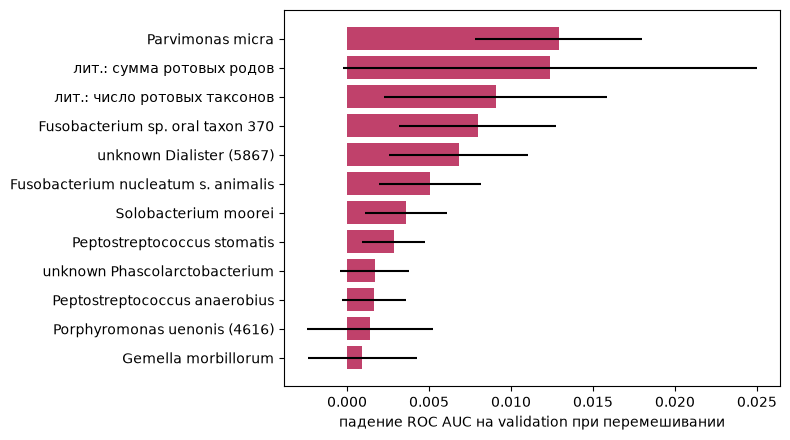

In [15]:
prep_v, model_v = pipe_val.prep, pipe_val.model
Xv = apply_preprocessing(validation_df, prep_v, True)
short = [TAXA[i].split(" [")[0] for i in prep_v["keep"]]
dup = pd.Series(short).duplicated(keep=False).values
names = [f"{s} ({TAXA[i].split('_')[-1].rstrip(']')})" if dp else s for s, i, dp in zip(short, prep_v["keep"], dup)]
names += ["лит.: сумма ротовых родов", "лит.: число ротовых таксонов", "богатство", "индекс Шеннона"]
in_lit = [("ротовой род (Wirbel, Thomas)" if genus(TAXA[i]) in LIT_GENERA else "—") for i in prep_v["keep"]] + ["литературный признак"] * 2 + ["Thomas 2019"] + ["—"]
Xtr_f = apply_preprocessing(train_df, prep_v, True); rng = np.random.default_rng(SEED); rows = []
for j in np.argsort(-model_v.rf.feature_importances_)[:15]:
    drops = []
    for _ in range(10):
        Xs = Xv.copy(); Xs[:, j] = rng.permutation(Xs[:, j]); drops.append(auc_val - roc_auc_score(y_val, model_v.predict_proba(Xs)[:, 1]))
    rows.append((names[j], np.mean(drops), np.std(drops, ddof=1), "выше" if Xtr_f[y_tr == 1, j].mean() > Xtr_f[y_tr == 0, j].mean() else "ниже", in_lit[j]))
imp = pd.DataFrame(rows, columns=["признак", "падение AUC", "sd", "при КРР", "в литературе"]).sort_values("падение AUC", ascending=False).reset_index(drop=True)
print(imp.head(12).round(4).to_string())
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 4.5)); plt.barh(top["признак"], top["падение AUC"], xerr=top["sd"], color=np.where(top["при КРР"] == "выше", "#c0416b", "#2a8c82"))
plt.xlabel("падение ROC AUC на validation при перемешивании"); plt.tight_layout(); plt.show()

In [16]:
# Гипотезы из статей: одномерно, только на train, AUC внутри каждой страны (> 0.5 — выше у больных); p — Стауфер по странам, порог 0.05 / 7
def taxa_like(prefixes):
    return [i for i, c in enumerate(TAXA) if any(c.split(" [")[0].startswith(p) for p in prefixes)]


ORAL_EXTRA = ["Streptococcus anginosus", "Streptococcus australis", "Streptococcus constellatus", "Streptococcus mutans",
              "Streptococcus oralis", "Streptococcus parasanguinis", "Streptococcus sanguinis", "Streptococcus vestibularis",
              "Streptococcus salivarius", "Veillonella atypica", "Veillonella dispar", "Veillonella parvula", "Veillonella sp.",
              "Haemophilus parainfluenzae", "Granulicatella adiacens", "Atopobium parvulum", "Alloprevotella tannerae",
              "Prevotella intermedia", "Prevotella nigrescens", "Prevotella oris", "Mogibacterium timidum"]
SCFA = ["Faecalibacterium prausnitzii", "Roseburia", "Eubacterium rectale", "butyrate-producing", "Anaerostipes hadrus",
        "Coprococcus", "Butyrivibrio", "Eubacterium hallii"]
Xh = taxa_matrix(train_df); lg = lambda idx: np.log10(Xh[:, idx].sum(axis=1) + PSEUDO)
HYP = [("6 ротовых родов, сумма", "Wirbel 2019; Thomas 2019", "выше", lg(MARKER_IDX)),
       ("богатство ротовых видов", "Thomas 2019", "выше", (Xh[:, MARKER_IDX + taxa_like(ORAL_EXTRA)] > 0).sum(axis=1)),
       ("продуценты бутирата", "лекция; Wirbel 2019", "ниже", lg(taxa_like(SCFA))),
       ("сульфидогены Bilophila, Desulfovibrio", "Yazici 2017; Nguyen 2020", "выше", lg(taxa_like(["Bilophila", "Desulfovibrio"]))),
       ("C. scindens (вторичные жёлчные кислоты)", "Osswald 2026", "выше", lg(taxa_like(["Clostridium scindens"]))),
       ("Atopobium parvulum (ранние стадии)", "Yachida 2019", "выше", lg(taxa_like(["Atopobium parvulum"]))),
       ("общее богатство видов", "Thomas 2019", "выше", (Xh > 0).sum(axis=1))]
rows = []
for name, src, expect, v in HYP:
    au = [roc_auc_score(y_tr[co_d == co], v[co_d == co]) for co in COHORTS]
    alt = "greater" if expect == "выше" else "less"      # односторонний p в ожидаемую сторону (двусторонний терял бы направление)
    p = combine_pvalues([mannwhitneyu(v[(co_d == co) & (y_tr == 1)], v[(co_d == co) & (y_tr == 0)], alternative=alt).pvalue for co in COHORTS], method="stouffer")[1]
    ok = (p < 0.05 / len(HYP)) and ((np.mean(au) > 0.5) == (expect == "выше"))
    rows.append([name, src, expect] + [round(a, 2) for a in au] + [round(np.mean(au), 3), f"{p:.0e}", "да" if ok else "нет"])
print(pd.DataFrame(rows, columns=["признак", "источник", "ожидание"] + COHORTS + ["ср. AUC", "p", "подтверждается"]).to_string(index=False))

                                признак                 источник ожидание  AUS  CHI  FRA  GER  USA  ср. AUC     p подтверждается
                 6 ротовых родов, сумма Wirbel 2019; Thomas 2019     выше 0.90 0.88 0.76 0.83 0.74    0.823 6e-25             да
                богатство ротовых видов              Thomas 2019     выше 0.76 0.76 0.57 0.78 0.64    0.701 2e-10             да
                    продуценты бутирата      лекция; Wirbel 2019     ниже 0.33 0.28 0.30 0.26 0.47    0.326 2e-08             да
  сульфидогены Bilophila, Desulfovibrio Yazici 2017; Nguyen 2020     выше 0.61 0.58 0.72 0.51 0.68    0.620 1e-04             да
C. scindens (вторичные жёлчные кислоты)             Osswald 2026     выше 0.53 0.70 0.46 0.56 0.48    0.547 3e-02            нет
     Atopobium parvulum (ранние стадии)             Yachida 2019     выше 0.49 0.58 0.54 0.53 0.50    0.527 1e-01            нет
                  общее богатство видов              Thomas 2019     выше 0.73 0.49 0.51 0.50 0.3

## 13. Сдвиг train → test и отвергнутые идеи
Метки test не нужны; все идеи не приняты.

In [17]:
# Только метаданные и таксоны test (меток в test нет); в обучении и выборе модели test не участвует
rows = []
for co in COHORTS:
    a, b = train[train["cohort"] == co], test[test["cohort"] == co]
    rows.append((co, len(a), len(b), (a["gender"] == "M").mean(), (b["gender"] == "M").mean(), a["age"].median(), b["age"].median(),
                 np.log10(a["library_size"]).median(), np.log10(b["library_size"]).median()))
print(pd.DataFrame(rows, columns=["страна", "n train", "n test", "доля M train", "доля M test", "возраст train", "возраст test",
                                  "log10 глубина train", "log10 глубина test"]).round(2).to_string(index=False))
Xa, Xb = taxa_matrix(train), taxa_matrix(test)
print("доля нулей в таксонах: train %.3f | test %.3f" % ((Xa == 0).mean(), (Xb == 0).mean()))
Z = np.log10(np.vstack([Xa, Xb]) + PSEUDO); src = np.r_[np.zeros(len(Xa)), np.ones(len(Xb))]
pz = cross_val_predict(RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=N_JOBS), Z, src,
                       cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print("отличает ли лес test от train по таксонам: AUC = %.3f (0.5 — не отличает)" % roc_auc_score(src, pz))

страна  n train  n test  доля M train  доля M test  возраст train  возраст test  log10 глубина train  log10 глубина test
   AUS       79      30          0.62         0.53           69.0          64.5                 7.42                7.41
   CHI       99      29          0.68         0.48           64.0          64.0                 7.30                7.30
   FRA       80      34          0.50         0.50           63.5          64.5                 7.46                7.44
   GER       87      33          0.59         0.52           60.0          64.0                 7.30                7.38
   USA       70      34          0.83         0.47           63.0          64.5                 7.50                7.49
доля нулей в таксонах: train 0.720 | test 0.721
отличает ли лес test от train по таксонам: AUC = 0.486 (0.5 — не отличает)


In [18]:
# Сводка v4: расчёты — скрипты experiments/v4_*.py (стенд v3core.py, правило как в разделе 9 + другие фолды, random_state 2025)
IDEAS = pd.DataFrame([
    ("модели: параметры леса, ExtraTrees, бустинг, веса смеси, ранги", 12, 0.0014, 0.0020, "нет"),
    ("признаки: остатки для лит. признаков, нелинейная глубина, бутират, сульфидогены, роды, отбор", 11, -0.0001, 0.0003, "нет"),
    ("устойчивость к глубине: без глубины, наклон по странам, веса, коррекция скора", 6, -0.0004, 0.0003, "нет"),
    ("пол как ещё одна ковариата в остатках (в train 64 % мужчин, в test 50 %)", 1, -0.0136, -0.0037, "нет"),
], columns=["группа идей", "вариантов", "лучший Δ CV", "лучший Δ новая страна", "принято"])
print(IDEAS.to_string(index=False))
print("Принято по правилу (Δ новая страна >= +0.005, Δ выровненные >= +0.005, Δ CV >= -0.005): 0 из 30. Финальная модель — v3.")

                                                                                 группа идей  вариантов  лучший Δ CV  лучший Δ новая страна принято
                              модели: параметры леса, ExtraTrees, бустинг, веса смеси, ранги         12       0.0014                 0.0020     нет
признаки: остатки для лит. признаков, нелинейная глубина, бутират, сульфидогены, роды, отбор         11      -0.0001                 0.0003     нет
               устойчивость к глубине: без глубины, наклон по странам, веса, коррекция скора          6      -0.0004                 0.0003     нет
                    пол как ещё одна ковариата в остатках (в train 64 % мужчин, в test 50 %)          1      -0.0136                -0.0037     нет
Принято по правилу (Δ новая страна >= +0.005, Δ выровненные >= +0.005, Δ CV >= -0.005): 0 из 30. Финальная модель — v3.


## 14. Финальная модель и таблица ответа
Обучение на 415 образцах; последняя ячейка — ответ.

In [19]:
final = GutPipeline(**FINAL).fit(train)
p_test = np.round(final.predict(test), DECIMALS)
assert np.array_equal(p_test, np.round(GutPipeline(**FINAL).fit(train).predict(test), DECIMALS)), "два запуска дают разные вероятности"
assert np.allclose(final.predict(test[test.columns[::-1]].iloc[:50]), p_test[:50], atol=10.0 ** -DECIMALS), "результат зависит от порядка столбцов/числа строк"
submission = pd.DataFrame({"sample_id": test["sample_id"].values, "label": p_test})
assert list(submission.columns) == ["sample_id", "label"] and len(submission) == len(test) and submission["sample_id"].is_unique
assert (submission["sample_id"].values == test["sample_id"].values).all()
assert not submission.isna().any().any() and submission["label"].between(0, 1).all()
print(f"признаков в финальной модели: {len(final.prep['keep'])} таксонов + 4 литературных")
print(f"таблица готова: {len(submission)} строк; label = вероятность КРР; min {p_test.min():.3f}, медиана {np.median(p_test):.3f}, max {p_test.max():.3f}")

признаков в финальной модели: 681 таксонов + 4 литературных
таблица готова: 160 строк; label = вероятность КРР; min 0.098, медиана 0.501, max 0.961


In [20]:
pd.set_option("display.max_rows", None)
submission

,sample_id,label
0,S0125,0.372711
1,S0242,0.406653
2,S0053,0.254558
3,S0173,0.193126
4,S0453,0.503183
5,S0342,0.478053
6,S0438,0.178460
7,S0222,0.275175
8,S0429,0.438491
9,S0134,0.233171
